In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1

In [3]:
def bwf(filter_order, cutoff_frequency, sampling_frequency):
    analog_b, analog_a = butter(filter_order, cutoff_frequency, analog = True, btype='low')

    print(analog_b)
    print(analog_a)

    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

In [4]:
filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000
ripple = 0.5

In [5]:
digital_b, digital_a = bwf(filter_order, cutoff_frequency, sampling_frequency)
print("\ndigital b: ", digital_b)

print("\ndigital a: ",digital_a)

[1.e+12]
[1.00000000e+00 2.61312593e+03 3.41421356e+06 2.61312593e+09
 1.00000000e+12]

digital b:  [1.29607191e-05 5.18428766e-05 7.77643148e-05 5.18428766e-05
 1.29607191e-05]

digital a:  [ 1.         -3.67388572  5.07378356 -3.12116011  0.72146964]


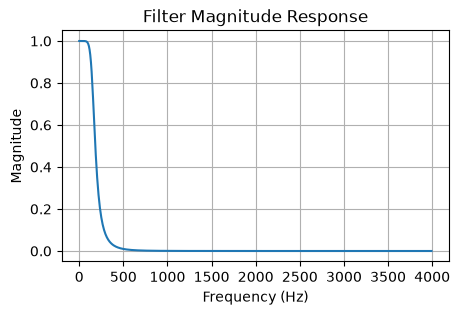

In [6]:
frequency, magnitude_response = freqz(digital_b, digital_a, fs = sampling_frequency)

plt.figure(figsize=(5,3))
plt.plot(frequency, np.abs(magnitude_response))
plt.title('Filter Magnitude Response')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.grid(True)
plt.show()

c:\Users\devah\Documents\ICT MU\Sem 5\DSIP\Lab\.venv\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\devah\Documents\ICT MU\Sem 5\DSIP\Lab\.venv\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


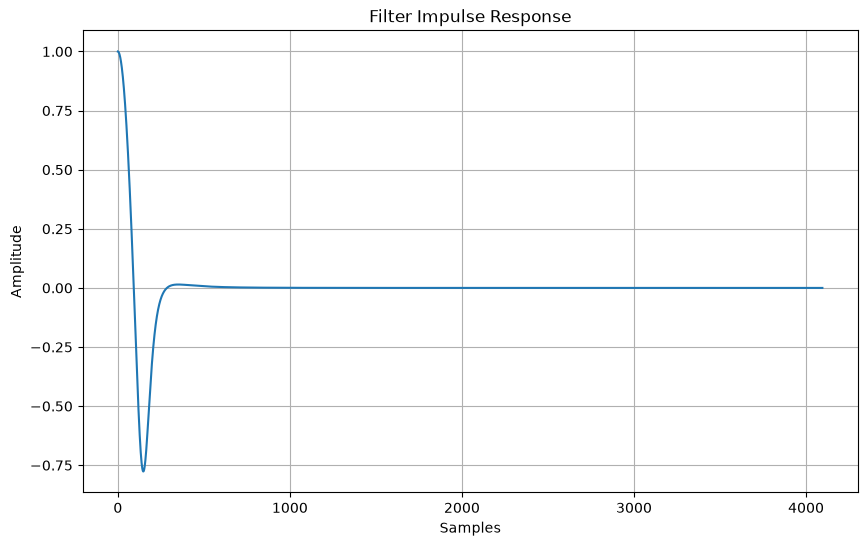

In [7]:
frequency, impulse_response = freqz(digital_b, digital_a, fs=sampling_frequency, worN=4096)
plt.figure(figsize=(10, 6))
plt.plot(impulse_response)
plt.title('Filter Impulse Response')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

In [8]:
def chebyshef(filter_order, cutoff_frequency, sampling_frequency):
    analog_b, analog_a = cheby1(filter_order, ripple, cutoff_frequency, analog = True, btype='low')

    print(analog_b)
    print(analog_a)

    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

In [9]:
filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000
ripple = 0.5

In [10]:
digital_b, digital_a = chebyshef(filter_order, cutoff_frequency, sampling_frequency)
print("\ndigital b: ", digital_b)

print("\ndigital a: ", digital_a)

[3.57846895e+11]
[1.00000000e+00 1.19738566e+03 1.71686621e+06 1.02545528e+09
 3.79050657e+11]

digital b:  [5.04743397e-06 2.01897359e-05 3.02846038e-05 2.01897359e-05
 5.04743397e-06]

digital a:  [ 1.         -3.83541526  5.53394882 -3.55962935  0.86118134]


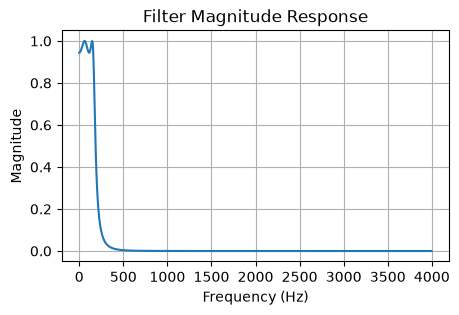

In [11]:
frequency, magnitude_response = freqz(digital_b, digital_a, fs = sampling_frequency, worN = 1024)

plt.figure(figsize=(5,3))
plt.plot(frequency, np.abs(magnitude_response))
plt.title('Filter Magnitude Response')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.grid(True)
plt.show()